# TP 1 — Construire un pipeline NLP classique

**Cours NLP et Transformers — CY Tech**

---

## Avant de commencer

**Faites tout de suite : `Fichier` → `Enregistrer une copie dans Drive`.**
Sans cela vous travaillez sur une copie temporaire et vous perdrez tout en fermant l'onglet.

## Objectif

Construire un pipeline de classification de texte **complet et correctement évalué**, de bout en bout :

`texte brut → prétraitement → représentation → modèle → mesure`

Le but n'est pas d'obtenir le meilleur score. Le but est que **chaque décision du pipeline soit justifiée** et que le score annoncé soit crédible.

## Ce qui est attendu

1. Un jeu de données étiqueté construit à partir du corpus brut
2. Un prétraitement et une représentation TF–IDF
3. Une **baseline** avant tout modèle
4. **Au moins deux modèles** de machine learning comparés
5. Une évaluation avec accuracy, précision, rappel, F1 et matrice de confusion
6. Une **analyse des erreurs** rédigée (partie 8) — c'est la partie la plus importante

## Les deux erreurs qui coûtent des points

- Vectoriser **avant** de découper train/test → fuite de données, tout le TP est invalidé
- Afficher une matrice de confusion sans la commenter

---

## 0. Environnement

Rien à installer : tout est déjà présent dans Colab. Exécutez simplement la cellule.

In [ ]:
import re
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environnement prêt.")

Environnement prêt.


## 1. Charger le corpus

Le corpus **Tiny Shakespeare** : environ 40 000 lignes extraites de plusieurs pièces de Shakespeare.

C'est du **texte brut, sans aucune étiquette**. C'est volontaire : une grande partie du travail d'un data scientist consiste à transformer une matière première non structurée en un problème d'apprentissage bien posé.

In [ ]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

texte = urllib.request.urlopen(URL).read().decode("utf-8")

print(f"{len(texte):,} caractères")
print(f"{len(texte.splitlines()):,} lignes")
print("\n--- 300 premiers caractères ---\n")
print(texte[:300])

1,115,394 caractères
40,000 lignes

--- 300 premiers caractères ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


## 2. Observer la structure avant de coder

**Avant d'écrire quoi que ce soit, regardez vos données.** C'est la première règle du métier, et c'est celle qu'on saute le plus souvent.

Affichez un extrait plus long et répondez aux questions ci-dessous.

In [ ]:
# TODO : afficher les caractères 1000 à 2500 du corpus
print(texte[1000:2500])

Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

**Questions — répondez ici avant de continuer :**

1. Quelle est la structure répétitive du texte ? Qu'est-ce qui sépare deux blocs ?
2. Quelle information exploitable comme étiquette est déjà présente dans le texte ?
3. Cette étiquette existait-elle vraiment, ou faut-il l'annoter à la main ?

> *Vos réponses :*
>
> 1. Structure du texte : en blocs de texte précédés par une ligne au format "Nom du personnage:" et séparés par des sauts de lignes (lignes vides).
> 2. Le nom du personnage qui parle juste avant son bloc de dialogue.
> 3. Elle existe déjà.

---

💡 **Le point à retenir.** Vous venez de trouver une cible qui existait déjà dans les données, sans le moindre annotateur humain. C'est exactement le principe de l'**apprentissage auto-supervisé** vu en cours : on fabrique le signal à partir de la structure du texte lui-même. C'est le mécanisme qui rend possible l'entraînement des grands modèles de langage.

## 3. Construire le jeu de données étiqueté

La fonction de parsing vous est donnée : ce n'est pas l'objet du TP, et une regex mal réglée vous ferait perdre une heure.

**Lisez-la quand même**, vous devrez justifier ce qu'elle garde et ce qu'elle jette.

In [ ]:
def parser_repliques(txt: str) -> pd.DataFrame:
    """Découpe le corpus en répliques (locuteur, texte).

    Format attendu dans le corpus :

        NOM DU LOCUTEUR:
        première ligne de la réplique
        seconde ligne de la réplique

    Les blocs sont séparés par une ligne vide.
    """
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

print(f"{len(df):,} répliques extraites")
print(f"{df['locuteur'].nunique()} locuteurs distincts")
df.head(10)

7,094 répliques extraites
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"
8,Second Citizen,"One word, good citizens."
9,First Citizen,"We are accounted poor citizens, the patricians..."


### 3.1 Explorer la distribution

Avant de choisir votre tâche, il faut savoir à quoi ressemble la distribution des classes.

Les 20 locuteurs les plus fréquents :
             Locuteur  Répliques
0          GLOUCESTER        211
1      DUKE VINCENTIO        189
2            MENENIUS        161
3               ROMEO        160
4           PETRUCHIO        155
5          CORIOLANUS        148
6    KING RICHARD III        137
7            ISABELLA        127
8             LEONTES        124
9              JULIET        124
10           SICINIUS        117
11     KING EDWARD IV        109
12    QUEEN ELIZABETH        105
13              LUCIO        101
14            WARWICK         98
15    KING RICHARD II         98
16             BRUTUS         91
17  HENRY BOLINGBROKE         90
18             TRANIO         90
19         BUCKINGHAM         89
Longueur médiane : 14.0 mots
Longueur moyenne : 27.2 mots


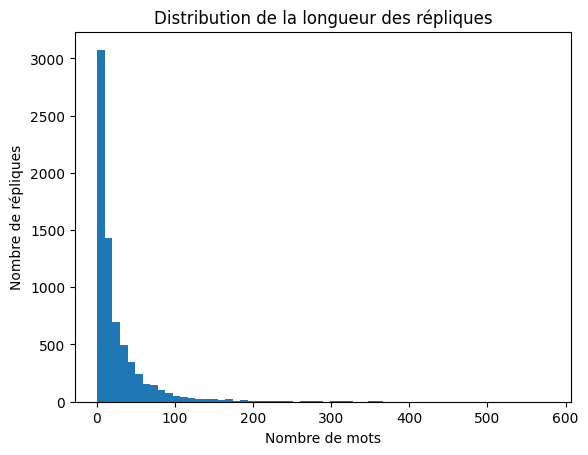

In [ ]:
# TODO : afficher les 20 locuteurs les plus fréquents et leur nombre de répliques
top20 = df["locuteur"].value_counts().head(20).reset_index()
top20.columns = ["Locuteur", "Répliques"]

print("Les 20 locuteurs les plus fréquents :")
print(top20)

# TODO : afficher la distribution de la longueur des répliques (en nombre de mots)
#        -> médiane, moyenne, et un histogramme


# Longueur des répliques en nombre de mots
df["longueur_mots"] = df["replique"].str.split().str.len()

# médiane et moyenne
mediane = df["longueur_mots"].median()
moyenne = df["longueur_mots"].mean()

print(f"Longueur médiane : {mediane:.1f} mots")
print(f"Longueur moyenne : {moyenne:.1f} mots")

# affichage en histogramme longueur des répliques en nb de mots
plt.hist(df["longueur_mots"], bins=60)
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre de répliques")
plt.title("Distribution de la longueur des répliques")
plt.show()

**Questions :**

1. La distribution des locuteurs est-elle équilibrée ? Que se passerait-il si vous gardiez les 297 locuteurs ?
2. Quelle est la longueur médiane d'une réplique ? Est-ce beaucoup pour de la classification de texte ?
3. Quelle conséquence cette longueur aura-t-elle sur votre vecteur TF–IDF ?

> *Vos réponses :*
1. La distribution des locuteurs n'est pas équilibrée, certains ont nettement plus de répliques que d'autres (par exemple Gloucester en a 211 tandis que Buckingham en a 89). Si on gardait les 297 locuteurs, on aurait un problème de classification multiclasse à 297 classes. Les classes ayant peu de répliques seront difficiles à apprendre et le modèle risque de favoriser les locuteurs qui ont le plus de répliques.

2. La longueur médiane d'un réplique : 14.0 mots. Pour de la classification de texte, une réplique courte risque de contenir peu d'informations discriminantes. Avec seulement quelques mots, il peut être difficile de déterminer quel locuteur les a prononcés.

3. Une réplique de peu de mots sera représentée par un vecteur qui contiendra beaucoup de 0 (surtout si le vocabulaire est très grand). Beaucoup de mots peuvent être rares, donc leur score TF-IDF peut être élevé. Les répliques courtes peuvent avoir des représentations assez différentes simplement parce qu'elles contiennent peu de termes donc
avec 297 locuteurs, la classification devient encore plus difficile.

## 4. Définir la tâche

À vous de poser le problème. Vous devez décider :

- **combien de locuteurs** vous gardez (le nombre de classes) ;
- s'il faut **filtrer les répliques trop courtes**, et à partir de quel seuil ;
- si vos classes sont suffisamment **équilibrées** pour que l'accuracy ait un sens.

Il n'y a pas une seule bonne réponse. Il y a des choix, et ils doivent être **justifiés et écrits**.

> **Votre choix et sa justification :**
>
> - Nombre de locuteurs retenus : 20 (choix du prof : 5)
> - Seuil de longueur minimale : 5 mots
> - Pourquoi : On garde les 20 locuteurs ayant le plus de répliques pour éviter d'avoir des classes très rares et difficiles à apprendre, tout en gardant un minimum de diversité entre les locuteurs. On supprimera les répliques de moins de 5 mots, car elles risquent de contenir trop peu d'information lexicale pour vraiment identifier le locuteur.


In [ ]:
# TODO : construire `donnees`, un DataFrame filtré contenant :
#          - colonne 'replique' : le texte
#          - colonne 'locuteur' : l'étiquette
#
# Contraintes :
#   - ne garder que les N locuteurs les plus fréquents (choisissez N)
#   - écarter les répliques trop courtes (choisissez le seuil)

N = 20
SEUIL = 5
top_locuteurs = df["locuteur"].value_counts().head(N).index

donnees = df[(df["locuteur"].isin(top_locuteurs)) &
             (df["longueur_mots"] >= SEUIL)][["replique", "locuteur"]].copy()

print(donnees['locuteur'].value_counts())
print(f"\n{len(donnees)} exemples retenus")

locuteur
GLOUCESTER           196
DUKE VINCENTIO       165
ROMEO                141
PETRUCHIO            133
MENENIUS             126
KING RICHARD III     116
JULIET               115
CORIOLANUS           110
ISABELLA             109
KING EDWARD IV       107
LEONTES               99
QUEEN ELIZABETH       98
KING RICHARD II       95
WARWICK               95
TRANIO                86
LUCIO                 83
SICINIUS              82
BUCKINGHAM            80
HENRY BOLINGBROKE     78
BRUTUS                67
Name: count, dtype: int64

2181 exemples retenus


## 5. ⚠️ Découper AVANT toute transformation

**C'est le point le plus important du TP.**

Tout composant qui **apprend quelque chose à partir des données** doit être ajusté sur le train seulement :

| Composant | Ce qu'il apprend en regardant les données |
|---|---|
| Vocabulaire TF–IDF | quels mots existent, et quelle colonne chacun occupe |
| Poids IDF | dans combien de documents chaque mot apparaît |
| Normalisation | la moyenne et l'écart-type de chaque variable |

Si vous vectorisez avant de découper, les fréquences du test participent au calcul de l'IDF. Votre modèle a alors utilisé une information issue du test : **votre score final sera surestimé et ne voudra plus rien dire.**

La discipline tient en deux lignes :

```python
X_train = vectorizer.fit_transform(train)   # fit + transform
X_test  = vectorizer.transform(test)        # transform SEULEMENT
```

Pensez à **stratifier** le découpage : sans cela, un locuteur peu représenté peut être absent du test.

In [ ]:
# TODO : découper en train / test
#   - 20 % pour le test
#   - stratifier sur le locuteur
#   - random_state=RANDOM_STATE pour que vos résultats soient reproductibles

X = donnees["replique"]
y = donnees["locuteur"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"train : {len(X_train)} exemples")
print(f"test  : {len(X_test)} exemples")

train : 1744 exemples
test  : 437 exemples


## 6. Représenter le texte

Vous allez transformer chaque réplique en vecteur TF–IDF.

`TfidfVectorizer` expose plusieurs paramètres qui sont autant de décisions de prétraitement. Regardez au moins ceux-ci et **choisissez consciemment** :

| Paramètre | Question qu'il pose |
|---|---|
| `lowercase` | la casse porte-t-elle du signal pour votre tâche ? |
| `ngram_range` | faut-il récupérer un peu d'ordre local avec des bigrammes ? |
| `min_df` | à partir de combien d'occurrences un mot mérite-t-il une colonne ? |
| `max_df` | faut-il écarter les mots omniprésents ? |
| `stop_words` | ⚠️ attention au piège vu en cours |
| `sublinear_tf` | 10 occurrences valent-elles vraiment 10 fois 1 occurrence ? |

> **Vos choix et leur justification :**

J'ai activé `lowercase` pour mettre tous les mots en minuscule car la casse ne semble pas vraiment apporter d'information pour identifier le locuteur et risquerait de créer des caractéristiques distinctes pour le même mot avec ou sans majuscule.

Pour `ngram=(1,2)` : on conversvera les unigrammes et bigrammes. Les unigrammes donnent le vocabulaire utilisé par le locuteur et les bigrammes permettent de récupérer un peu d'information sur l'ordre local des mots/des expressions caractéristiques.

Pour `min_df=2` : un terme doit apparaître au moins dans 2 répliques pour obtenir une colonne, ainsi on supprime les mots trop rares qui apportent trop peu d'information pour généraliser mais qui augmentent inutilement la taille du vecteur.

Pour `max_df=0.95` : on supprime les termes présents dans plus de 95% des répliques car trop fréquents pour réellement pouvoir discriminer les locuteurs.

Pas de stop words, car ce genre de mots (pronoms, "mais", "donc" etc) peuvent cosntituer des indices d'une manière de parler d'un locuteur.

`sublinear_tf = True` pour réduire l'effet des répétitions d'un même mot dans une réplique -> une occurrence et dix occurrences du même mot ne doivent pas nécessairement produire un poids dix fois supérieur. C'est surtout utile pour les répliques de longueurs différentes.

In [ ]:
# TODO : instancier le vectoriseur, l'ajuster sur le train, transformer les deux jeux

vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.95,
    stop_words=None,
    sublinear_tf=True
)

Xtr = vectoriseur.fit_transform(X_train) # fit_transform sur le train
Xte = vectoriseur.transform(X_test) # transform sur le test

print(f"Taille du vocabulaire : {len(vectoriseur.vocabulary_):,}")
print(f"Matrice train : {Xtr.shape}")
print(f"Sparsité : {Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]):.4%} de valeurs non nulles")

Taille du vocabulaire : 9,229
Matrice train : (1744, 9229)
Sparsité : 0.4069% de valeurs non nulles


**Questions :**

1. Quelle proportion de votre matrice est constituée de zéros ? Pourquoi est-ce structurellement inévitable ?
2. Que se passerait-il si vous stockiez cette matrice en tableau NumPy dense ?
3. Affichez les 15 termes ayant le poids IDF le plus élevé, puis les 15 plus faibles. Le résultat vous surprend-il ?

> *Vos réponses :*

1. 0,4069% de valeurs non nulles donc 100-0,4069=99,5931% de zéros. C'est inévitable avec le TF-IDF car, le vocabulaire étant grand (9229), chaque réplique ne contient qu'une petite partie de tous les termes du vocabulaire, et chaque terme du vocabulaire correspond à une dimension d'un vecteur représentant une réplique.

2. La matrice a : `1744 * 9229 ~= 16` millions de valeurs. Un tableau Numpy dense en `float64` = 8 octets. Donc la matrice prendrait `16M*8 = 128Mo`, dont la majorité qui stocke des 0 inutiles.

3. Le résultat n'est pas surprenant : les termes qui ont l'idf le plus faible (donc très présent dans les répliques) sont des mots types conjonction de coordination, pronoms, articles/déterminants très communs pour construire une phrase. Les mots/bigrammes avec un IDF élevés sont en général des expressions ou termes plus spécifiques ("absolute power", "abstinence" ...) qui apparaissent dans très peu de répliques donc qui peuvent être très discriminants.

In [ ]:
# TODO : afficher les 15 termes de plus fort et de plus faible IDF
#        (indice : vectoriseur.idf_ et vectoriseur.get_feature_names_out())

termes = vectoriseur.get_feature_names_out()
idf = vectoriseur.idf_

idf_df = pd.DataFrame({"terme": termes,"idf": idf})

print("15 termes avec l'IDF le plus élevé :")
print(idf_df.nlargest(15, "idf"))

print("\n15 termes avec l'IDF le plus faible :")
print(idf_df.nsmallest(15, "idf"))


15 termes avec l'IDF le plus élevé :
             terme       idf
5         about my  7.365898
6        about our  7.365898
8         about to  7.365898
10       above our  7.365898
16  absolute power  7.365898
17      abstinence  7.365898
18        abundant  7.365898
19          accent  7.365898
20       accent of  7.365898
23        accident  7.365898
27      accusation  7.365898
29      accuse him  7.365898
31         achieve  7.365898
35          act of  7.365898
37         actions  7.365898

15 termes avec l'IDF le plus faible :
     terme       idf
207    and  1.767476
7015   the  1.779898
7813    to  1.815525
5141    of  2.094609
6900  that  2.172941
9033   you  2.210681
4680    my  2.268066
3421    in  2.311777
4977   not  2.353042
3562    is  2.357487
2318   for  2.450795
732     be  2.503504
8813  with  2.516475
4364    me  2.524339
1125   but  2.556427


## 7. Modéliser

### 7.1 D'abord la baseline — sans exception

Une baseline vous donne le **plancher** : le score qu'on atteint sans rien apprendre.

Sans elle, vous ne pouvez pas savoir si 65 % est un bon résultat ou un résultat catastrophique. C'est un réflexe professionnel, pas une formalité pédagogique.

In [ ]:
# TODO : entraîner un DummyClassifier (strategy='most_frequent' puis 'stratified')
#        et afficher son accuracy et son F1 macro sur le test

# Baseline 1 : toujours prédire le locuteur le plus fréquent
dummy_most = DummyClassifier(strategy="most_frequent",random_state=RANDOM_STATE)
dummy_most.fit(Xtr, y_train)
y_pred_most = dummy_most.predict(Xte)

print("=== most_frequent ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_most):.3f}")
print(f"F1 macro : {f1_score(y_test, y_pred_most, average='macro'):.3f}")

=== most_frequent ===
Accuracy : 0.089
F1 macro : 0.008


> **Score de la baseline :**
>
> Tout modèle qui ne dépasse pas nettement ce score n'apprend rien d'utile.

### 7.2 Au moins deux modèles

Choisissez-en au moins deux parmi : `MultinomialNB`, `LogisticRegression`, `LinearSVC`.

Pour chacun, notez **pourquoi** il est adapté (ou non) à une représentation TF–IDF très creuse et de grande dimension.

⚠️ Vos classes sont probablement déséquilibrées. Regardez ce que fait `class_weight='balanced'` et dites si vous le gardez.

In [ ]:
# TODO : entraîner au moins deux modèles et stocker leurs prédictions
#        Suggestion : un dictionnaire {nom_du_modele: predictions}


# Modèle 1 : régression logistique
modele_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE
)

modele_lr.fit(Xtr, y_train)
pred_lr = modele_lr.predict(Xte)


# Modèle 2 : SVM linéaire
modele_svc = LinearSVC(
    class_weight="balanced",
    random_state=RANDOM_STATE
)

modele_svc.fit(Xtr, y_train)
pred_svc = modele_svc.predict(Xte)


# stockage des prédictions
resultat = {
    "LogisticRegression": pred_lr,
    "LinearSVC": pred_svc
}

LogisticRegression : construit une combinaison linéaire des caractéristiques (mots & bigrammes) x_i en appliquant à chacune leur poids tf-idf w_i. Chaque mot ou bigramme peut recevoir un w_i négatif ou positif selon son association avec un locuteur.
La régression logistique fonctionne directement avec des matrices creuses (sparse) sans avoir à transformer les milliers de 0 en une représentation dense,  et supporte bien un grand nombre de caractéristiques par rapport au nombre d'exemples. Elle peut donc apprendre des relations du type : « la présence de certains mots/bigrammes rend le locuteur A plus probable que le locuteur B ».

Pour LinearSVC : cherche un hyperplan linéaire pour séparer les classes. Certains termes ou certaines expressions sont plus caractéristiques de certains locuteurs, et LinearSVC apprend une frontière permettant de les distinguer. Elle fonctionne avec des vecteurs de très grande dimension, prend des matrices sparse et est en général rapide et peu couteuse sur ce type de réprésentation Tf-IDF.

`class_weight='balanced'` : attribue automatiquement un poids plus élevé aux classes minoritaires et un poids plus faible aux classes majoritaires. Cela permet d'éviter que le modèle privilégie les locuteurs ayant beaucoup de répliques. Chaque erreur sur une réplique d'un personnage qui en a peu compte davantage que les erreurs faites sur une personnage qui a beaucoup de répliques. On conserve ce paramètre car notre distribution des locuteurs est déséquilibrée.

## 8. Évaluer et analyser

### 8.1 Les métriques

Rappel du cours : sur des classes déséquilibrées, **l'accuracy ment**. Reportez toujours le F1, et précisez la méthode d'agrégation.

- `average='macro'` : moyenne non pondérée sur les classes → traite les classes rares à égalité
- `average='weighted'` : pondérée par les effectifs → dominée par les classes fréquentes

Indiquez explicitement laquelle vous utilisez et pourquoi.

> Les classes sont déséquilibrées, donc nous utilisons principalement le F1 macro, qui calcule le F1 de chaque locuteur puis réalise une moyenne non pondérée. Chaque locuteur contribue donc autant au score, y compris les locuteurs minoritaires.

In [ ]:
# TODO : pour chaque modèle, afficher accuracy, précision, rappel et F1 (macro et weighted)
#        puis un classification_report complet
#        Présentez la comparaison sous forme de tableau (DataFrame)


# Stocker les métriques
comparaison = []

for nom, predictions in resultat.items():
    comparaison.append({
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision macro": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Precision weighted": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall weighted": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1 weighted": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

# Tableau comparatif
comparaison_df = pd.DataFrame(comparaison)

print(comparaison_df.round(3))

# rapport complet du modèle
for nom, predictions in resultat.items():
    print(f"\n{'=' * 60}")
    print(nom)
    print("=" * 60)

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

               Modèle  Accuracy  Precision macro  Recall macro  F1 macro  \
0  LogisticRegression     0.316            0.312         0.330     0.313   
1           LinearSVC     0.341            0.346         0.345     0.342   

   Precision weighted  Recall weighted  F1 weighted  
0               0.311            0.316        0.305  
1               0.345            0.341        0.339  

LogisticRegression
                   precision    recall  f1-score   support

           BRUTUS       0.16      0.23      0.19        13
       BUCKINGHAM       0.31      0.50      0.38        16
       CORIOLANUS       0.35      0.36      0.36        22
   DUKE VINCENTIO       0.24      0.27      0.26        33
       GLOUCESTER       0.11      0.03      0.04        39
HENRY BOLINGBROKE       0.27      0.25      0.26        16
         ISABELLA       0.65      0.50      0.56        22
           JULIET       0.22      0.22      0.22        23
   KING EDWARD IV       0.27      0.18      0.22        2

Comparaison des deux modèles : sur toutes les métriques, LinearSVC est meilleur que LogisticRegression.

Pour l'accuracy : 34.1% de toutes les répliques du test ont été attribuées au bon locuteur. C'est relativement faible mais toujours meilleur que la baseline précédente (accuracy de 0.89%). Le modèle trouve donc bien des indices linguistiques pour reconnaître les locuteurs, même si ça ne lui permet pas de faire en majorité des bonnes prédictions.

Le F1 macro = 34.2% suggère donc que les performances ne sont pas uniquement dues aux classes majoritaires. Comparé à l'accuracy, on voit que le modèle obtient des performances assez comparables lorsqu'on donne le même poids à chaque locuteur.

Precision et recall sont proches (34.5%, 34.6%).

### 8.2 La matrice de confusion

Affichez-la pour votre meilleur modèle. **Une matrice affichée sans commentaire ne vaut rien** — c'est la partie 8.3 qui compte.

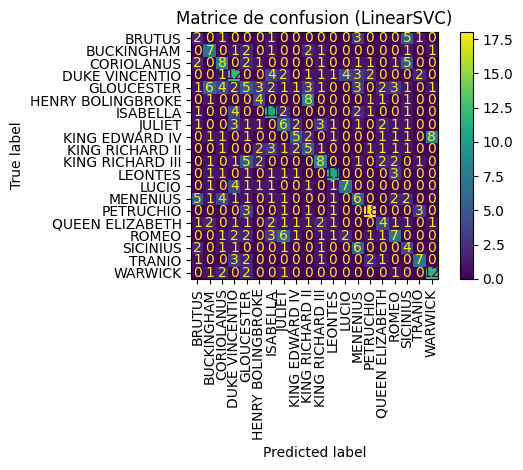

In [ ]:
# TODO : afficher la matrice de confusion du meilleur modèle
#        (indice : ConfusionMatrixDisplay.from_predictions)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    resultat["LinearSVC"],
    xticks_rotation="vertical"
)

plt.title("Matrice de confusion (LinearSVC)")
plt.tight_layout()
plt.show()

### 8.3 Analyse des erreurs — la partie la plus importante

Répondez précisément, en vous appuyant sur des exemples concrets tirés de vos données.

1. **Quelles paires de locuteurs sont le plus confondues ?** Formulez une hypothèse : viennent-ils de la même pièce ? ont-ils un registre proche ? un nombre d'exemples très différent ?

2. **Sortez cinq répliques mal classées et lisez-les.** Auriez-vous su répondre vous-même ? Si non, que dit cela sur le plafond de performance atteignable ?

3. **Regardez les coefficients de votre modèle linéaire** (`coef_`) : quels termes pèsent le plus pour chaque classe ? Y a-t-il des **noms propres** parmi eux ?

   Si oui, posez-vous la vraie question : votre modèle reconnaît-il le **style d'un personnage**, ou identifie-t-il simplement la **pièce** dans laquelle la réplique apparaît ? Ce n'est pas du tout la même tâche, et cela change ce que vous pouvez affirmer sur votre modèle.

4. **Votre score est-il crédible ?** Reprenez votre pipeline et vérifiez qu'aucune information du test n'a pu remonter vers l'entraînement.

> *Votre analyse :*

1. **Locuteurs les plus confondus :**
King Edward IV souvent prédit Warwick (8 fois)
Henry Bolingbroke souvent prédit King Richard II (8 fois)
Gloucester souvent prédit Buckingham (6 fois)
Roméo souvent prédit Juliette (6 fois)
Sicinius souvent prédit Menenius (6 fois)

Les inverse ne sont pas forcément vrais.
Effectivement, certains de ces personnages ont des similarités qui peuvent expliquer cette confusion. Tous ces duos font partie de la même pièce, donc discutent probablement de choses similaires qui appartiennent au même univers théâtral. Par exemple, pour Roméo et Juliette, ces derniers partagent sans doute beaucoup de vocabulaire lié à l'amour, aux sentiments ou à la famille et à leur relation. Henry Bolingbroke et King Richard II sont cousins et rivaux, donc très liés et doivent avoir un registre de langage très similaire porté sur la politique, les évènements qui les relient, et leur relation. Tous ces duos doivent sans doute souvent figurer dans des scènes communes, utiliser un vocabulaire commun autour de leur rôles (royaume, politique, confrontations...), et le modèle peut avoir du mal à distinguer deux locuteurs lorsqu'ils parlent des mêmes sujets.


In [ ]:
erreurs = pd.DataFrame({
    "replique": X_test,
    "locuteur_reel": y_test,
    "locuteur_predit": resultat["LinearSVC"]
})

erreurs = erreurs[erreurs["locuteur_reel"] != erreurs["locuteur_predit"]]

cinq_erreurs = erreurs.sample(
    n=min(5, len(erreurs)),
    random_state=RANDOM_STATE
)

for i, ligne in cinq_erreurs.iterrows():
    print("=" * 80)
    print(f"Locuteur réel   : {ligne['locuteur_reel']}")
    print(f"Locuteur prédit : {ligne['locuteur_predit']}")
    print(f"Réplique        : {ligne['replique']}")

Locuteur réel   : KING RICHARD II
Locuteur prédit : CORIOLANUS
Réplique        : He does me double wrong That wounds me with the flatteries of his tongue. Discharge my followers: let them hence away, From Richard's night to Bolingbroke's fair day.
Locuteur réel   : KING RICHARD II
Locuteur prédit : ISABELLA
Réplique        : Can sick men play so nicely with their names?
Locuteur réel   : LEONTES
Locuteur prédit : ROMEO
Réplique        : Your actions are my dreams; You had a bastard by Polixenes, And I but dream'd it. As you were past all shame,-- Those of your fact are so--so past all truth: Which to deny concerns more than avails; for as Thy brat hath been cast out, like to itself, No father owning it,--which is, indeed, More criminal in thee than it,--so thou Shalt feel our justice, in whose easiest passage Look for no less than death.
Locuteur réel   : ROMEO
Locuteur prédit : GLOUCESTER
Réplique        : I doubt it not; and all these woes shall serve For sweet discourses in our time

Pour la plupart, la réplique est courte et ne donne pas assez d'indices lexicaux pour qu'un humain puisse savoir à qui l'attribuer correctement.

Néanmoins, pour celles plus longues, il y avait des indices pertinents que le modèle n'a pas relevé, par exemple pour la 1ère : Richard et Bolingbroke sont évoqués dans la phrase, mais le modèle a prédit un personnage d'un tout autre univers théâtral. Cela montre une limite du modèle TF-IDF : il ne "comprend" pas que Richard désigne le locuteur lui-même/que Bolingbroke appartient à la même pièce.

De même pour la 3e réplique qui évoque un personnage nommé Polixenes, probablement romain donc bien plus probable d'appartenir à un locuteur des pièces de Shakespeare se situant à cette époque plutôt qu'à Roméo.

Cela montre que TF-IDF ne comprend pas les relations sémantiques entre les mots et les personnages. Les noms propres peuvent pourtant constituer des indices très discriminants. Le modèle peut donc exploiter certaines corrélations lexicales sans réellement comprendre le contexte de la réplique. Ces résultats renforcent également l'hypothèse selon laquelle le modèle peut apprendre des caractéristiques propres aux pièces plutôt que véritablement le style individuel des personnages.

In [ ]:
termes = vectoriseur.get_feature_names_out()

for i, locuteur in enumerate(modele_svc.classes_):
    coefficients = modele_svc.coef_[i]

    indices = np.argsort(coefficients)[-15:][::-1]

    print("\n" + "=" * 70)
    print(f"LOCUTEUR : {locuteur}")
    print("=" * 70)

    for indice in indices:
        print(f"{termes[indice]:30s} {coefficients[indice]:+.4f}")

for i, locuteur in enumerate(modele_svc.classes_):
    coefficients = modele_svc.coef_[i]

    indices = np.argsort(coefficients)[:10]

    print("\n" + "=" * 70)
    print(f"Termes les plus négatifs pour : {locuteur}")
    print("=" * 70)

    for indice in indices:
        print(f"{termes[indice]:30s} {coefficients[indice]:+.4f}")


LOCUTEUR : BRUTUS
others                         +1.3431
this true                      +1.0519
he will                        +1.0214
the people                     +1.0212
and eyes                       +0.9481
this news                      +0.9151
people                         +0.9099
is this                        +0.9070
he                             +0.9044
know it                        +0.8961
ho                             +0.8887
aediles                        +0.8869
they have                      +0.8806
your way                       +0.8778
we do                          +0.8479

LOCUTEUR : BUCKINGHAM
lord                           +2.2170
grace                          +1.3515
royal                          +1.1145
your grace                     +1.0812
my lord                        +1.0368
catesby                        +1.0081
lord this                      +0.9430
good time                      +0.8518
says your                      +0.8388
deep                  

3. Le modèle utilise beaucoup de noms propres et de références à d'autres personnages pour identifier une classe. Cela peut suggérer qu'il apprend en partie le contexte narratif de la pièce, pas uniquement le style du locuteur. Par exemple, Juliette est associée fortement à `romeo`, Petruchio à `kate` et `hortensio`, King Edward IV à `warwick`, `lewis`, etc... Le modèle a donc appris que quand il rencontre du vocabulaire associé à tel nom propre A, il est fort probable que le locuteur soit B, au lieu d'apprendre une relation telle que "la manière de parler dans cette réplique ressemble à celle du locuteur B".
Le modèle peut donc en partie apprendre des associations entre certains personnages, lieux ou événements et le locuteur.

4. Oui.